# MNIST Handwritten Digit Recognition — MLP & CNN Benchmark

Comparison of multilayer perceptrons and convolutional neural networks for handwritten digit classification using TensorFlow/Keras.


In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [2]:
from tensorflow.keras.datasets import mnist
from matplotlib import pyplot as plt
from tensorflow.keras.utils import to_categorical

(trainX, trainY), (testX, testY) = mnist.load_data()
print(trainX.shape)
print(testX.shape)
trainX = trainX.astype('float32') / 255.0
testX = testX.astype('float32') / 255.0
trainX1 = trainX.reshape((trainX.shape[0], 28, 28, 1))
testX1 = testX.reshape((testX.shape[0], 28, 28, 1))
print(trainX1.shape)
print(testX1.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(10000, 28, 28)
(60000, 28, 28, 1)
(10000, 28, 28, 1)


## Multilayer Perceptron (MLP) models


In [3]:
train_x_flatten = trainX.reshape(trainX.shape[0], -1)   # The "-1" makes reshape flatten the
test_x_flatten = testX.reshape(testX.shape[0], -1)   # The "-1" makes reshape flatten the remaining dimensions

In [4]:
print(train_x_flatten.shape)


(60000, 784)


In [5]:

trainY = to_categorical(trainY)
testY = to_categorical(testY)
print(trainY.shape)
print(trainY[0])

(60000, 10)
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [6]:
callback = tf.keras.callbacks.EarlyStopping(monitor='loss', patience=4)

input_num_units = 784
hidden_num_units = 32
output_num_units = 10

epochs = 60
batch_size = 32

MLP1_model = tf.keras.Sequential([
    layers.Dense(units=hidden_num_units, input_dim=train_x_flatten.shape[1], activation='relu'),
    layers.Dense(units=output_num_units, activation='softmax')
])
MLP1_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:



MLP1_model.summary()

trained_MLP1_model = MLP1_model.fit(train_x_flatten, trainY, epochs=epochs, batch_size=64, validation_split = 0.2, verbose=1, callbacks=[callback])


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8641 - loss: 0.4812 - val_accuracy: 0.9273 - val_loss: 0.2630
Epoch 2/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9286 - loss: 0.2518 - val_accuracy: 0.9407 - val_loss: 0.2131
Epoch 3/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9416 - loss: 0.2051 - val_accuracy: 0.9438 - val_loss: 0.1920
Epoch 4/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9502 - loss: 0.1749 - val_accuracy: 0.9518 - val_loss: 0.1706
Epoch 5/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9568 - loss: 0.1512 - val_accuracy: 0.9544 - val_loss: 0.1566
Epoch 6/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9620 - loss: 0.1329 - val_accuracy: 0.9582 - val_loss: 0.1403
Epoch 7/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9661 - loss: 0.1201 - val_accuracy: 0.9597 - val_loss: 0.1366
Epoch 8/60
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9694 - loss: 0.1079 - val_accuracy: 0.

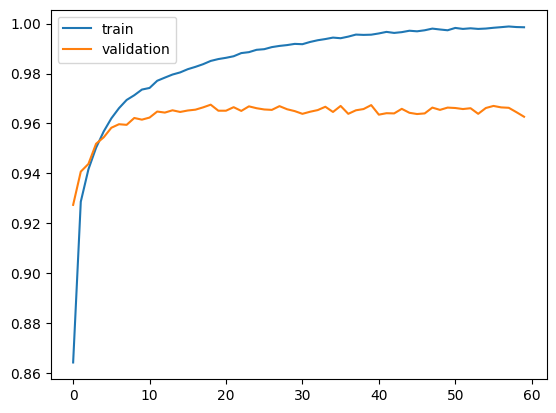

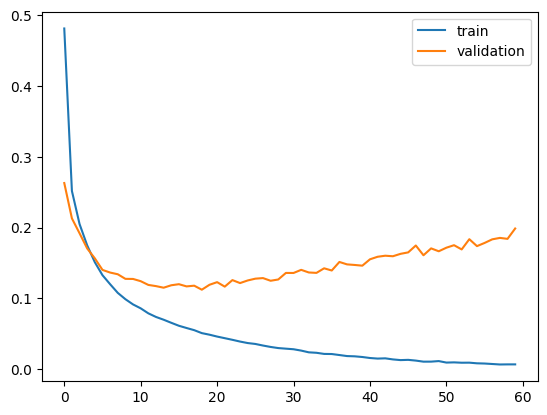

accuracy training 0.9985416531562805
accuracy validation 0.9626666903495789
précision models on test dataset :0.9653000235557556


In [8]:

plt.plot(trained_MLP1_model.history['accuracy'])
plt.plot(trained_MLP1_model.history['val_accuracy'])
plt.legend(['train','validation'])
plt.show()

plt.plot(trained_MLP1_model.history['loss'])
plt.plot(trained_MLP1_model.history['val_loss'])
plt.legend(['train','validation'])
plt.show()

print('accuracy training',trained_MLP1_model.history['accuracy'][-1])
print('accuracy validation',trained_MLP1_model.history['val_accuracy'][-1])

test_results = {}

test_results['MLP1_model'] = MLP1_model.evaluate(test_x_flatten,testY, verbose=0)[1]
print("précision models on test dataset :" + str(test_results['MLP1_model']))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


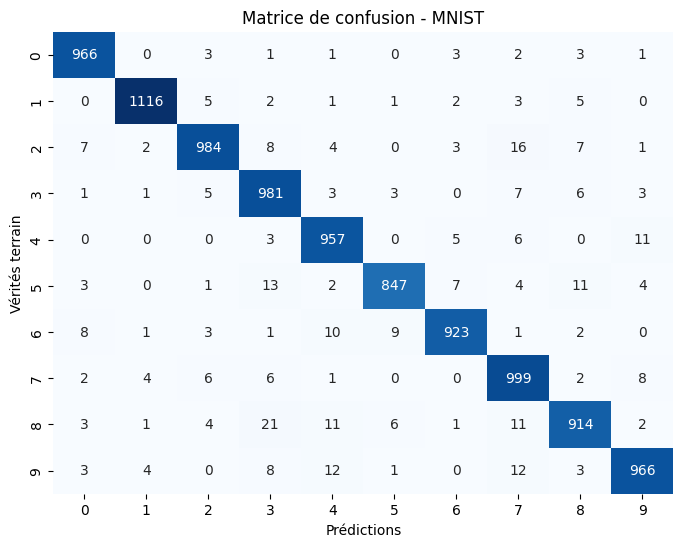


Rapport de classification :
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.98      0.99      1135
           2       0.97      0.95      0.96      1032
           3       0.94      0.97      0.96      1010
           4       0.96      0.97      0.96       982
           5       0.98      0.95      0.96       892
           6       0.98      0.96      0.97       958
           7       0.94      0.97      0.96      1028
           8       0.96      0.94      0.95       974
           9       0.97      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.96      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [9]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred = MLP1_model.predict(test_x_flatten)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(testY, axis=1)

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matrice de confusion - MNIST')
plt.xlabel('Prédictions')
plt.ylabel('Vérités terrain')
plt.show()

print("\nRapport de classification :")
print(classification_report(y_true, y_pred_classes))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,354 (849.04 KB)

 Trainable params: 217,354 (849.04 KB)

 Non-trainable params: 0 (0.00 B)

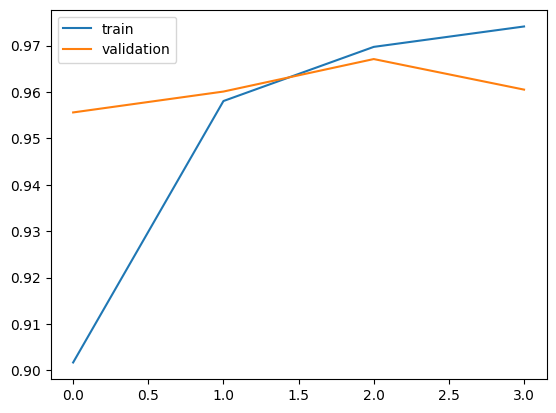

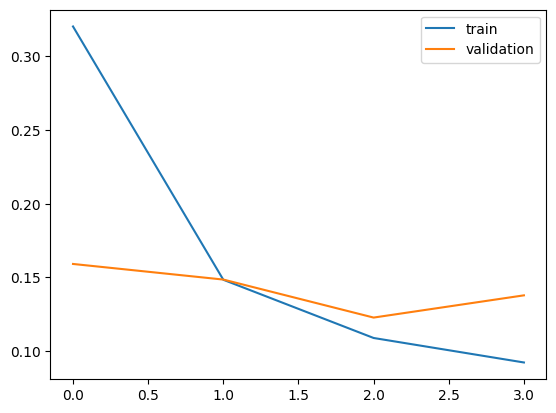

accuracy training 0.9741041660308838
accuracy validation 0.9605000019073486


In [10]:
input_num_units = 784
hidden_num_units = 32*4
output_num_units = 10

batch_size = 32

MLP2_model = tf.keras.Sequential([
    layers.Dense(units=hidden_num_units, input_dim=input_num_units, activation='relu'),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dense(units=output_num_units, activation='softmax')
])

MLP2_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

MLP2_model.summary()

trained_MLP2_model = MLP2_model.fit(train_x_flatten, trainY, epochs=epochs, batch_size=batch_size, validation_split = 0.2, verbose=0, callbacks=[callback])

plt.plot(trained_MLP2_model.history['accuracy'])
plt.plot(trained_MLP2_model.history['val_accuracy'])
plt.legend(['train','validation'])
plt.show()

plt.plot(trained_MLP2_model.history['loss'])
plt.plot(trained_MLP2_model.history['val_loss'])
plt.legend(['train','validation'])
plt.show()

print('accuracy training',trained_MLP2_model.history['accuracy'][-1])
print('accuracy validation',trained_MLP2_model.history['val_accuracy'][-1])

test_results['MLP2_model'] = MLP2_model.evaluate(test_x_flatten,testY, verbose=0)[1]

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,354 (849.04 KB)

 Trainable params: 217,354 (849.04 KB)

 Non-trainable params: 0 (0.00 B)

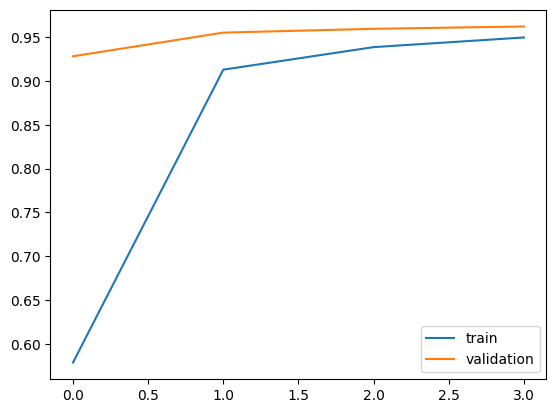

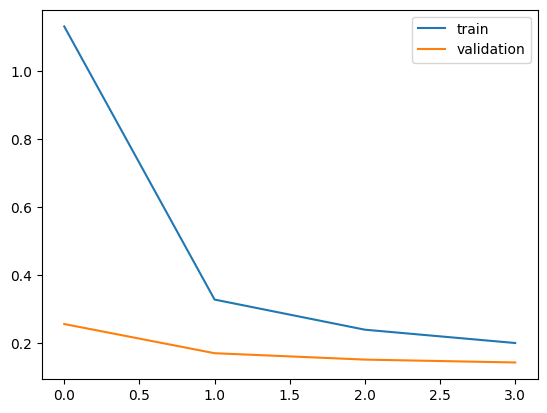

accuracy training 0.9497083425521851
accuracy validation 0.9622499942779541


In [11]:
input_num_units = 784
hidden_num_units = 32*4
output_num_units = 10

batch_size = 32*8

MLP_regul_model = tf.keras.Sequential([
    layers.Dense(units=hidden_num_units, input_dim=input_num_units, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=hidden_num_units,  activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(units=output_num_units,  activation='softmax')
])

MLP_regul_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

MLP_regul_model.summary()

trained_MLP_regul_model = MLP_regul_model.fit(train_x_flatten, trainY, epochs=epochs, batch_size=batch_size, validation_split = 0.2, verbose=0, callbacks=[callback])


plt.plot(trained_MLP_regul_model.history['accuracy'])
plt.plot(trained_MLP_regul_model.history['val_accuracy'])
plt.legend(['train','validation'])
plt.show()

plt.plot(trained_MLP_regul_model.history['loss'])
plt.plot(trained_MLP_regul_model.history['val_loss'])
plt.legend(['train','validation'])
plt.show()

print('accuracy training',trained_MLP_regul_model.history['accuracy'][-1])
print('accuracy validation',trained_MLP_regul_model.history['val_accuracy'][-1])

test_results['MLP_regul_model'] = MLP_regul_model.evaluate(test_x_flatten,testY, verbose=0)[1]

## Convolutional Neural Network (CNN) models


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 5, 5, 32)       │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,162 (4.54 KB)

 Trainable params: 1,162 (4.54 KB)

 Non-trainable params: 0 (0.00 B)

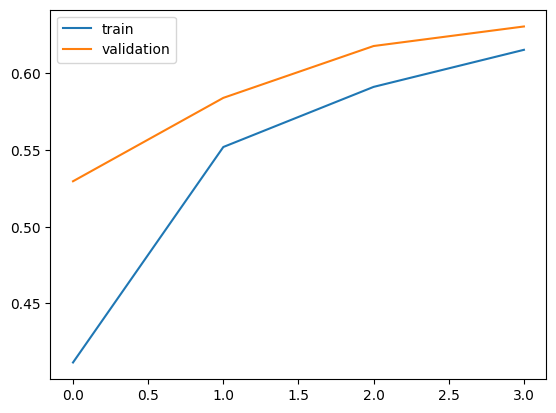

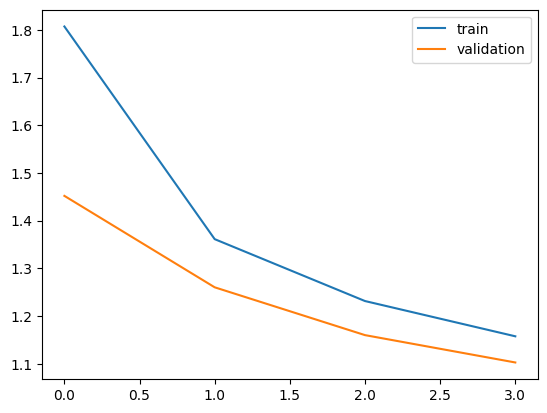

accuracy training 0.6154375076293945
accuracy validation 0.6306666731834412


In [12]:
input_num_units = 64
hidden_num_units = 64
output_num_units = 10

input_reshape = (28, 28, 1)

batch_size = 64

CNNmodel_baseline = tf.keras.Sequential([
    layers.InputLayer(input_shape=input_reshape),
    layers.Convolution2D(32, 5,5, activation='relu'),
    layers.MaxPooling2D((4,4)),
    layers.Flatten(),
    layers.Dense(units=output_num_units, activation='softmax')
])

CNNmodel_baseline.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

CNNmodel_baseline.summary()

trained_CNNmodel_baseline = CNNmodel_baseline.fit(trainX, trainY, epochs=epochs, batch_size=batch_size, validation_split = 0.2, verbose=0, callbacks=[callback])

plt.plot(trained_CNNmodel_baseline.history['accuracy'])
plt.plot(trained_CNNmodel_baseline.history['val_accuracy'])
plt.legend(['train','validation'])
plt.show()

plt.plot(trained_CNNmodel_baseline.history['loss'])
plt.plot(trained_CNNmodel_baseline.history['val_loss'])
plt.legend(['train','validation'])
plt.show()

print('accuracy training',trained_CNNmodel_baseline.history['accuracy'][-1])
print('accuracy validation',trained_CNNmodel_baseline.history['val_accuracy'][-1])

test_results['CNNmodel_baseline'] = CNNmodel_baseline.evaluate(testX,testY, verbose=0)[1]

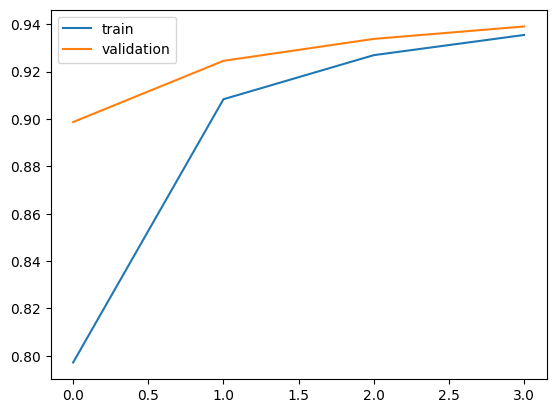

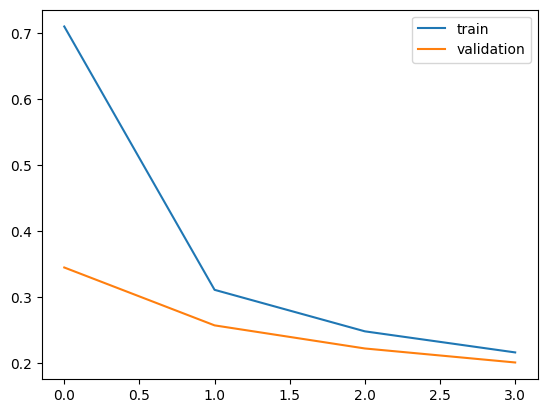

accuracy training 0.9354166388511658
accuracy validation 0.9390000104904175


In [13]:
input_num_units = 64
hidden_num_units = 64
output_num_units = 10

input_reshape = (28, 28, 1)

batch_size = 64

CNNmodel = tf.keras.Sequential([
    layers.InputLayer(input_shape=input_reshape),
    layers.Convolution2D(32, 3,3, activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(units=output_num_units, activation='softmax')
])

CNNmodel.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

trained_CNNmodel = CNNmodel.fit(trainX, trainY, epochs=epochs, batch_size=batch_size, validation_split = 0.2, verbose=0, callbacks=[callback])

plt.plot(trained_CNNmodel.history['accuracy'])
plt.plot(trained_CNNmodel.history['val_accuracy'])
plt.legend(['train','validation'])
plt.show()

plt.plot(trained_CNNmodel.history['loss'])
plt.plot(trained_CNNmodel.history['val_loss'])
plt.legend(['train','validation'])
plt.show()

print('accuracy training',trained_CNNmodel.history['accuracy'][-1])
print('accuracy validation',trained_CNNmodel.history['val_accuracy'][-1])

test_results['CNNmodel'] = CNNmodel.evaluate(testX,testY, verbose=0)[1]

In [16]:
pd.DataFrame(test_results, index=['Accuracy']).T

,Accuracy
MLP1_model,0.9653
MLP2_model,0.9654
MLP_regul_model,0.9619
CNNmodel_baseline,0.6290
CNNmodel,0.9406
